
========== Normal Conditions ==========

Evacuation Priorities:
A1 Riverside | Risk: 0.76 | Priority: CRITICAL
A2 Market | Risk: 0.53 | Priority: HIGH
A3 Hillview | Risk: 0.28 | Priority: NORMAL

Rescue Assignments:
Area Priority Team Shelter  People Evacuated  Travel Minutes
  A1 CRITICAL   T1      S1                60              18
  A1 CRITICAL   T2      S1                20              18
  A2     HIGH   T2      S2                30              14
  A2     HIGH   T3      S2                25              14
  A3   NORMAL   T3      S2                15              17

Summary:
Scenario: Normal Conditions
Total People: 170
Evacuated Safely: 150
People Remaining: 20
Evacuation Rate (%): 88.2
Travel Minutes: 81
Teams Used: 3

========== Road Blocked and Shelter Closed ==========

Evacuation Priorities:
A1 Riverside | Risk: 0.76 | Priority: CRITICAL
A2 Market | Risk: 0.53 | Priority: HIGH
A3 Hillview | Risk: 0.28 | Priority: NORMAL

Rescue Assignments:
Area Priority Team Shelter  

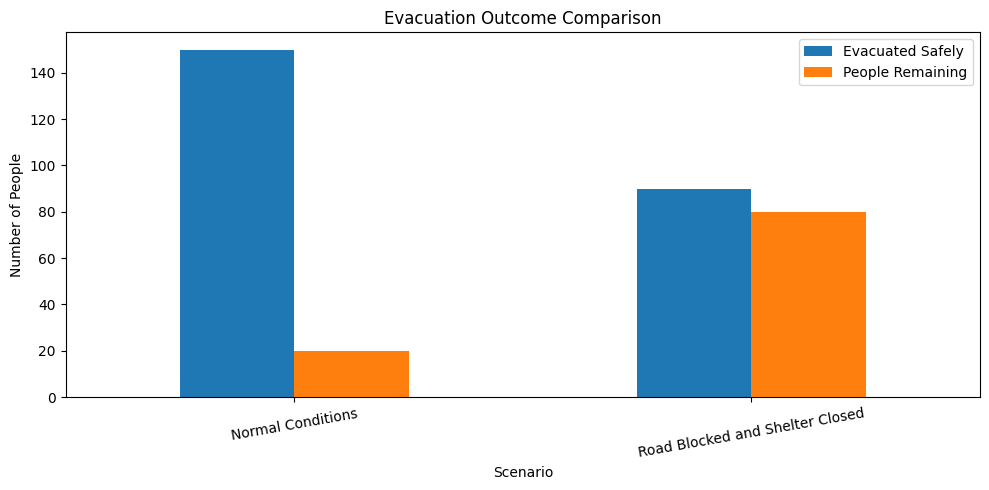

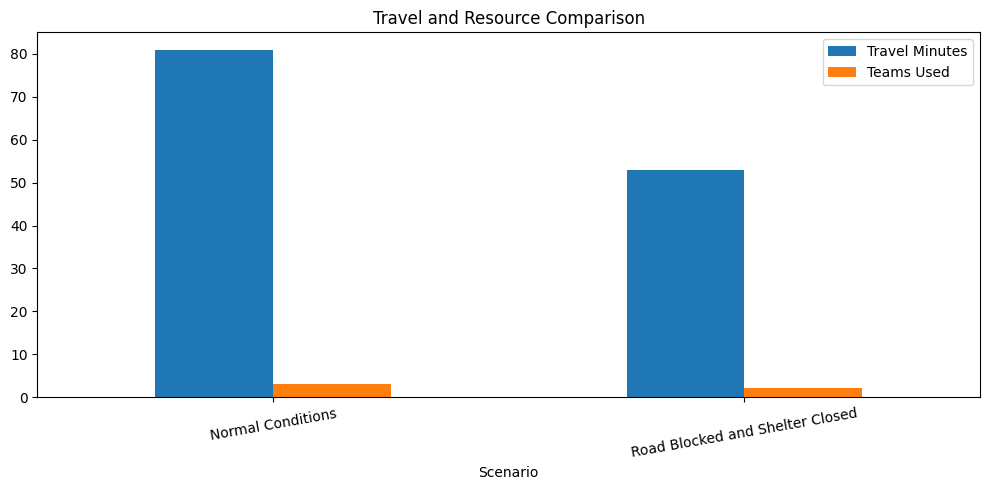

In [3]:
from copy import deepcopy
import pandas as pd
import matplotlib.pyplot as plt

# 1. Knowledge Representation

areas = {
    "A1": {"name": "Riverside", "people": 80, "flood": 0.90,
           "road": 0.80, "reports": 0.90},
    "A2": {"name": "Market", "people": 55, "flood": 0.60,
           "road": 0.90, "reports": 0.70},
    "A3": {"name": "Hillview", "people": 35, "flood": 0.30,
           "road": 0.95, "reports": 0.40}
}

teams = {
    "T1": {"name": "Alpha", "capacity": 60, "available": True},
    "T2": {"name": "Bravo", "capacity": 50, "available": True},
    "T3": {"name": "Charlie", "capacity": 40, "available": True}
}

shelters = {
    "S1": {"name": "School Shelter", "capacity": 90, "available": True},
    "S2": {"name": "Community Hall", "capacity": 70, "available": True},
    "S3": {"name": "Sports Complex", "capacity": 60, "available": True}
}

roads = {
    ("Base", "A1"): {"time": 10, "condition": 0.90},
    ("Base", "A2"): {"time": 8, "condition": 0.95},
    ("Base", "A3"): {"time": 12, "condition": 0.95},
    ("A1", "S1"): {"time": 8, "condition": 0.85},
    ("A1", "S2"): {"time": 12, "condition": 0.80},
    ("A2", "S1"): {"time": 7, "condition": 0.90},
    ("A2", "S2"): {"time": 6, "condition": 0.95},
    ("A2", "S3"): {"time": 10, "condition": 0.85},
    ("A3", "S2"): {"time": 5, "condition": 0.95},
    ("A3", "S3"): {"time": 7, "condition": 0.90}
}


def get_road(u, v, road_map):
    return road_map.get((u, v), road_map.get((v, u)))


# 2. Rule-Based Reasoning and 3. Uncertainty Handling

def calculate_risk(area):
    return round(
        0.50 * area["flood"]
        + 0.20 * (1 - area["road"])
        + 0.30 * area["reports"],
        3
    )


def determine_priorities(area_data):
    priorities = {}

    for aid, area in area_data.items():
        risk = calculate_risk(area)

        if risk >= 0.70 or area["flood"] >= 0.85:
            priority = "CRITICAL"
        elif risk >= 0.45 or area["people"] >= 50:
            priority = "HIGH"
        else:
            priority = "NORMAL"

        priorities[aid] = {
            "risk": risk,
            "priority": priority
        }

    return priorities


# 4. Resource Allocation

def find_shelter(area_id, people, shelter_data, road_map):
    candidates = []

    for sid, shelter in shelter_data.items():
        if not shelter["available"]:
            continue

        if shelter["capacity"] < people:
            continue

        road = get_road(area_id, sid, road_map)

        if road is None or road["condition"] < 0.40:
            continue

        score = road["time"] + (1 - road["condition"]) * 20
        candidates.append((score, sid, road))

    if not candidates:
        return None, None

    _, sid, road = min(candidates, key=lambda x: x[0])
    return sid, road


# 5. Multi-Agent Coordination using CNP

def allocate_rescue_tasks(area_data, team_data, shelter_data,
                          road_map, priorities):

    team_state = deepcopy(team_data)
    shelter_state = deepcopy(shelter_data)

    remaining = {
        aid: area["people"] for aid, area in area_data.items()
    }

    assignments = []
    used_teams = set()
    total_safe = 0
    total_travel = 0

    ordered_areas = sorted(
        area_data.keys(),
        key=lambda aid: (
            {"CRITICAL": 0, "HIGH": 1, "NORMAL": 2}[
                priorities[aid]["priority"]
            ],
            -priorities[aid]["risk"]
        )
    )

    for aid in ordered_areas:
        while remaining[aid] > 0:
            bids = []

            for tid, team in team_state.items():
                if not team["available"] or team["capacity"] <= 0:
                    continue

                pickup = get_road("Base", aid, road_map)

                if pickup is None or pickup["condition"] < 0.40:
                    continue

                count = min(remaining[aid], team["capacity"])

                sid, drop = find_shelter(
                    aid, count, shelter_state, road_map
                )

                if sid is None:
                    continue

                count = min(count, shelter_state[sid]["capacity"])

                travel = pickup["time"] + drop["time"]

                penalty = (
                    (1 - pickup["condition"]) * 20
                    + (1 - drop["condition"]) * 20
                )

                bid = travel + penalty

                bids.append((bid, tid, sid, count, travel))

            if not bids:
                break

            bid, tid, sid, count, travel = min(
                bids, key=lambda x: x[0]
            )

            team_state[tid]["capacity"] -= count
            shelter_state[sid]["capacity"] -= count
            remaining[aid] -= count

            if team_state[tid]["capacity"] == 0:
                team_state[tid]["available"] = False

            assignments.append({
                "Area": aid,
                "Priority": priorities[aid]["priority"],
                "Team": tid,
                "Shelter": sid,
                "People Evacuated": count,
                "Travel Minutes": travel
            })

            total_safe += count
            total_travel += travel
            used_teams.add(tid)

    return {
        "assignments": assignments,
        "safe": total_safe,
        "remaining": sum(remaining.values()),
        "travel": total_travel,
        "teams_used": len(used_teams)
    }


# 6. Simulation and Evaluation

def run_scenario(name, area_data, team_data, shelter_data, road_map):
    priorities = determine_priorities(area_data)

    result = allocate_rescue_tasks(
        area_data, team_data, shelter_data, road_map, priorities
    )

    print("\n==========", name, "==========")

    print("\nEvacuation Priorities:")
    for aid, info in priorities.items():
        print(
            aid, area_data[aid]["name"],
            "| Risk:", info["risk"],
            "| Priority:", info["priority"]
        )

    print("\nRescue Assignments:")
    if result["assignments"]:
        print(pd.DataFrame(result["assignments"]).to_string(index=False))
    else:
        print("No feasible assignments.")

    total_people = sum(a["people"] for a in area_data.values())

    summary = {
        "Scenario": name,
        "Total People": total_people,
        "Evacuated Safely": result["safe"],
        "People Remaining": result["remaining"],
        "Evacuation Rate (%)": round(
            result["safe"] / total_people * 100, 1
        ),
        "Travel Minutes": result["travel"],
        "Teams Used": result["teams_used"]
    }

    print("\nSummary:")
    for key, value in summary.items():
        print(f"{key}: {value}")

    return summary


def main():
    normal = run_scenario(
        "Normal Conditions",
        deepcopy(areas),
        deepcopy(teams),
        deepcopy(shelters),
        deepcopy(roads)
    )

    changed_areas = deepcopy(areas)
    changed_teams = deepcopy(teams)
    changed_shelters = deepcopy(shelters)
    changed_roads = deepcopy(roads)

    changed_roads[("A1", "S1")]["condition"] = 0.0
    changed_shelters["S2"]["available"] = False

    disrupted = run_scenario(
        "Road Blocked and Shelter Closed",
        changed_areas,
        changed_teams,
        changed_shelters,
        changed_roads
    )

    comparison = pd.DataFrame([normal, disrupted])

    print("\n========== SCENARIO COMPARISON ==========")
    print(comparison.to_string(index=False))

    comparison.plot(
        x="Scenario",
        y=["Evacuated Safely", "People Remaining"],
        kind="bar",
        figsize=(10, 5),
        title="Evacuation Outcome Comparison"
    )
    plt.ylabel("Number of People")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

    comparison.plot(
        x="Scenario",
        y=["Travel Minutes", "Teams Used"],
        kind="bar",
        figsize=(10, 5),
        title="Travel and Resource Comparison"
    )
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()